# Capstone: Define and Solve an ML Problem

In [11]:
import pandas as pd
import numpy as np
import os 
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import OneHotEncoder 
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
import tensorflow.keras as keras
from sklearn.preprocessing import StandardScaler
import time

**Note**: As you work through the notebook, you can import additional packages as needed.

## Overview


In this capstone assignment, you will follow the machine learning life cycle and implement one of the supervised learning models you have learned so far in this course, along with a neural network, to solve a predictive problem.

This capstone spans two lab sessions.

- **Unit 5 Lab:** You will define a machine learning problem, explore and prepare your data, and train, test, evaluate and improve a traditional machine learning model (Parts 1–5).
- **Unit 6 Lab:** After completing Unit 6 on neural networks, you will apply a neural network to the same problem and compare the two approaches (Parts 6–7).

There is a checkpoint at the end of Part 5 that marks where to stop during the Unit 5 lab.

You will complete the following:

1. Choose your Data Set and Build Your DataFrame
2. Define Your ML Problem
3. Understand Your Data
4. Prepare Your Data
5. Train, Test, Evaluate and Improve a Traditional Machine Learning Model *(Unit 5 lab)*
6. Train, Test, Evaluate and Improve Neural Network *(Unit 6 lab)*
7. Compare Your Models and Reflect *(Unit 6 lab)*

**This is an individual assignment.** You are welcome to discuss ideas with your peers, but the code and written responses you submit must be your own.

**Note:** This capstone is intentionally less scaffolded than your weekly labs; that is by design. You are expected to make your own implementation choices, add code cells as needed, and document your reasoning throughout.

## Part 1: Choose Your Data Set and Build Your DataFrame


You will choose one of two data sets to work with for this capstone. In both cases, you will be solving a supervised learning binary classification problem by predicting one of two possible class labels. Both data sets have been used earlier in the course, so you are already familiar with their structure. 

**Option A: Census Income Data** (`censusData.csv`)
This data set contains demographic and employment information from the 1994 U.S. Census. You will use it to predict whether an individual's annual income exceeds $50,000. Your label column is `income_binary`, which contains two values: `<=50K` and `>50K`. You will need to convert this column into a binary numeric label (for example, 0 and 1) during data preparation.

**Option B: Airbnb NYC Listings Data** (`airbnbListingsData.csv`)
This data set contains information about Airbnb listings in New York City. You will use it to predict whether a listing is high-priced. The data set includes a new `price_category` column that classifies each listing as either "high price" or "low price" based on whether the listing’s price falls above or below the 75th percentile of all listing prices. Listings at or above the 75th percentile are labeled as `high`, while the remaining listings are labeled as `low`. You will need to convert this column into a binary numeric label (for example, 0 and 1) during data preparation.

**Note:**  These versions of the data sets differ slightly from the versions you have worked with in this program. For example, they may not include some of the preprocessing necessary for specific models. 

#### Load a Data Set and Save it as a Pandas DataFrame

The code cell below contains filenames (path + filename) for the two data sets available to you.

<b>Task:</b> In the code cell below, load your chosen data set using `pd.read_csv()` and save it to a DataFrame named `df`. Then call `df.head()` to inspect the first few row of the data set.

In [12]:
# File paths for both data sets
census_filename = os.path.join(os.getcwd(), "data_capstone", "censusData.csv")
airbnb_filename = os.path.join(os.getcwd(), "data_capstone", "airbnbListingsData.csv")

# Load your chosen dataset and save it to df
df = pd.read_csv(airbnb_filename)

df.head()

,name,description,neighborhood_overview,host_name,host_location,host_about,host_response_rate,host_acceptance_rate,host_is_superhost,host_listings_count,...,review_scores_location,review_scores_value,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month,n_host_verifications,price_category
0,Skylit Midtown Castle,"Beautiful, spacious skylit studio in the heart...",Centrally located in the heart of Manhattan ju...,Jennifer,"New York, New York, United States",A New Yorker since 2000! My passion is creatin...,0.80,0.17,True,8.0,...,4.86,4.41,False,3,3,0,0,0.33,9,low
1,"Whole flr w/private bdrm, bath & kitchen(pls r...","Enjoy 500 s.f. top floor in 1899 brownstone, w...",Just the right mix of urban center and local n...,LisaRoxanne,"New York, New York, United States",Laid-back Native New Yorker (formerly bi-coast...,0.09,0.69,True,1.0,...,4.71,4.64,False,1,1,0,0,4.86,6,low
2,"Spacious Brooklyn Duplex, Patio + Garden",We welcome you to stay in our lovely 2 br dupl...,NaN,Rebecca,"Brooklyn, New York, United States","Rebecca is an artist/designer, and Henoch is i...",1.00,0.25,True,1.0,...,4.50,5.00,False,1,1,0,0,0.02,3,high
3,Large Furnished Room Near B'way,Please don’t expect the luxury here just a bas...,"Theater district, many restaurants around here.",Shunichi,"New York, New York, United States",I used to work for a financial industry but no...,1.00,1.00,True,1.0,...,4.87,4.36,False,1,0,1,0,3.68,4,low
4,Cozy Clean Guest Room - Family Apt,"Our best guests are seeking a safe, clean, spa...",Our neighborhood is full of restaurants and ca...,MaryEllen,"New York, New York, United States",Welcome to family life with my oldest two away...,NaN,NaN,True,1.0,...,4.94,4.92,False,1,0,1,0,0.87,7,low


## Part 2: Define Your ML Problem

The first step of the machine learning life cycle involves defining your business problem. In the markdown cell below, you will clearly define what you are trying to predict and why it matters. 

<b>Task</b>: In the markdown cell below, answer all of the following questions:

1. Which data set did you choose?
2. What is your label? What are you predicting?
3. What features do you plan to use? (This list may change after you explore your data.)
5. Why does this problem matter? Using the business brief you read in the lab overview page, explain how the organization described there could use a model that predicts this label to create value or inform decisions for their client.

<Double click this Markdown cell to make it editable, and record your answers here.>
I chose the Airbnb NYC Listings data set.

My label is price_category, which classifies each listing as either high price or low price based on whether its price is above or below the 75th percentile. I am predicting whether a listing is high‑priced.

The features I plan to use include:

host_response_rate

host_acceptance_rate

number_of_reviews

number_of_reviews_ltm

number_of_reviews_l30d

review_scores_cleanliness

review_scores_location

review_scores_value

reviews_per_month

calculated_host_listings_count

instant_bookable

This problem matters because predicting whether a listing is high‑priced helps the organization understand pricing patterns across New York City. A model like this can help clients identify which host behaviors, listing characteristics, or review patterns are associated with higher prices. This can support better investment decisions, pricing strategies, and market analysis for property owners or investors.

## Part 3: Understand Your Data

Now that you have defined your problem, perform exploratory data analysis (EDA) with that problem in mind. Consider the following as you inspect your data:

1. What data preparation techniques would you like to use? These data preparation techniques may include:

    * handling missing values
    * finding and replacing outliers
    * performing feature engineering techniques such as one-hot encoding on categorical features
    * selecting appropriate features and removing irrelevant features
    * addressing class imbalance


2. What machine learning model would you like to use that is suitable for your predictive problem and data?
   * You may use one of the following models that you have worked with so far:
        - K-Nearest Neighbors (KNN)
        - Decision Tree
        - Logistic Regression
   * Are there other data preparation techniques that you will need to apply to build a balanced modeling data set for your problem and model? For example, will you need to scale your data?
 

3. How will you evaluate and improve the model's performance?
    * Are there specific evaluation metrics or methods that are appropriate for your problem, dataset, or selected model?
    
<b>Task</b>: In the code cells below, use the techniques you have learned in this course to inspect and analyze your data.

<b>Note</b>: You can add code cells if needed by going to the <b>Insert</b> menu and clicking on <b>Insert Cell Below</b> in the drop-down menu.

### Class Imbalance

Examine the distribution of your label column to determine whether class imbalance is present. Use at least one visualization to show the class distribution. In the **EDA Summary** below, you will discuss how you plan to address any observed imbalance during data preparation.

In [13]:
# YOUR CODE HERE
df['price_category'].value_counts(normalize=True) * 100

low     74.173863
high    25.826137
Name: price_category, dtype: float64

### Inspect and Analyze Your Data

Explore your features. Use summary statistics and visualizations to understand how your features are distributed and how they relate to the label. Identify issues such as missing values, outliers, or a feature that is irrelevant or redundant.

Think of the different techniques you have used to inspect and analyze your data in this course. These include using Pandas to apply data filters, using the Pandas `describe()` method to get insight into key statistics for each column, using the Pandas `dtypes` property to inspect the data type of each column, and using Matplotlib and Seaborn to detect outliers and visualize relationships between features and labels. 

Use at least one plot that visualizes a relationship between features and the label.

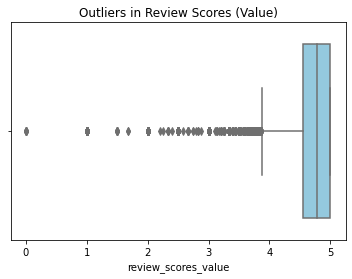

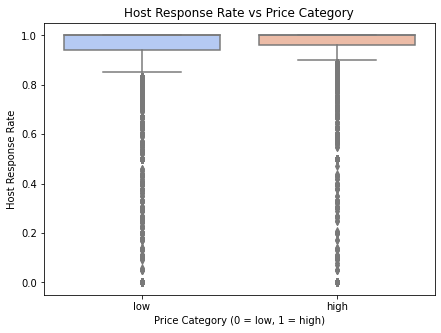

In [14]:
# YOUR CODE HERE
df.describe(include='all')

df.dtypes

df.isna().sum().sort_values(ascending=False)

plt.figure(figsize=(6,4))
sns.boxplot(data=df, x='review_scores_value', color='skyblue')
plt.title("Outliers in Review Scores (Value)")
plt.show()

plt.figure(figsize=(7,5))
sns.boxplot(data=df, x='price_category', y='host_response_rate', palette='coolwarm')
plt.title("Host Response Rate vs Price Category")
plt.xlabel("Price Category (0 = low, 1 = high)")
plt.ylabel("Host Response Rate")
plt.show()


### EDA Summary

<b>Task</b>: In the markdown cell below, summarize the key findings from your data exploration. Describe any patterns, anomalies, or data quality issues you identified and explain how those findings may influence your data preparation decisions. For example, your exploration may affect how you handle missing values, address class imbalance, or determine which features to keep or remove.

<Double click this Markdown cell to make it editable, and record your answers here.>

From exploring the Airbnb dataset, I found several key points that will guide my data preparation:

Class imbalance:  
The label price_category is imbalanced, with more listings labeled “low price” than “high price.” I will use stratified splitting and consider class weighting during modeling.

Missing values:  
Several numeric features contain missing values. I will fill numeric missing values using the median because it is robust to outliers. Boolean fields like instant_bookable will be filled with False.

Outliers:  
Review score features and some count‑based features show outliers. Since these models are sensitive to scale, I will scale the data rather than remove outliers.

Irrelevant features:  
Text columns such as listing descriptions, host bios, and neighborhood overviews are not needed for predicting price category and will be removed.

Useful features:  
Host response rate, acceptance rate, review scores, reviews per month, and listing counts show meaningful differences between high‑price and low‑price listings, so they will be kept.

Scaling:  
Because I plan to use Logistic Regression, I will scale all numeric features using StandardScaler.

These findings help ensure the dataset is clean, consistent, and ready for modeling.

### Ethical Considerations:

Machine learning models can cause harm when they reflect or amplify biases in the data they are trained on. 

<b>Task</b>: In the markdown cell below, answer both of the following questions:

1. What biases or ethical concerns might be present in your dataset? Think about who collected the data, how it was collected, and which groups of people appear in it. Are there features in the dataset that could serve as proxies for protected characteristics like race, gender, or socioeconomic status?
2. Who could be harmed by a model that makes incorrect predictions on this data, and how? Be specific about which groups are most at risk and what the real-world consequences of errors might look like.

<Double click this Markdown cell to make it editable, and record your answers here.>

1. Possible Biases in the Dataset
The Airbnb dataset may contain several forms of bias:

Neighborhood and location features can act as proxies for socioeconomic status or racial demographics.

Host‑related text fields may indirectly reveal protected characteristics such as nationality or gender.

Guest review scores may reflect personal bias rather than actual listing quality, meaning hosts in certain neighborhoods or demographic groups could receive systematically different ratings.

These biases can influence the model and lead it to learn patterns that reflect social inequalities rather than true price drivers.

2. Who Could Be Harmed and How
If the model incorrectly predicts whether a listing is high‑priced:

Hosts in lower‑income or historically marginalized neighborhoods could be misclassified as “low price,” reducing visibility or affecting pricing recommendations.

Property investors or clients using the model could make poor investment decisions if the model systematically favors certain neighborhoods or host profiles.

Hosts with fewer resources may be unfairly penalized if the model interprets these as signals of low price, even when the listing quality is high.

Incorrect predictions could lead to financial disadvantages, reduced bookings, or biased market insights.

## Part 4: Prepare Your Data

<b>Task</b>: In the code cell below, prepare your data for modeling. The specific steps you take will depend on what you found during your EDA and which model you plan to use. 

<b>Note</b>: You can add code cells if needed by going to the <b>Insert</b> menu and clicking on <b>Insert Cell Below</b> in the drop-down menu.

In [15]:
# YOUR CODE HERE
df['price_category'] = df['price_category'].map({'low': 0, 'high': 1})


features = [
    'host_response_rate',
    'host_acceptance_rate',
    'number_of_reviews',
    'number_of_reviews_ltm',
    'number_of_reviews_l30d',
    'review_scores_cleanliness',
    'review_scores_location',
    'review_scores_value',
    'reviews_per_month',
    'calculated_host_listings_count',
    'instant_bookable'
]


df_model = df[features + ['price_category']].copy()


for col in df_model.select_dtypes(include='number').columns:
    df_model[col] = df_model[col].fillna(df_model[col].median())


df_model['instant_bookable'] = df_model['instant_bookable'].fillna(False)


X = df_model.drop('price_category', axis=1)
y = df_model['price_category']


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1234, stratify=y
)


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Data Preparation Summary:

<b>Task</b>: In the markdown cell below, document the data preparation steps you took. For each decision, explain why you made it. For example, why did you handle missing values the way you did? Why did you keep or remove certain features? If a preparation step depends on the model you selected (for example, scaling for KNN but not for a decision tree), explain that as well.

<Double click this Markdown cell to make it editable, and record your answers here.>
To prepare my data for modeling, I took the following steps:

1. Selected relevant features:  
I kept numeric and behavioral features such as host response rate, acceptance rate, review scores, reviews per month, and listing counts because they are directly related to listing quality and host behavior, which can influence price. I removed text‑heavy or irrelevant columns because they are not needed for predicting price category and would require additional preprocessing.

2. Converted the label:  
The label price_category was originally stored as “high” or “low.” I converted it into a binary numeric label so it can be used in a classification model.

3. Handled missing values:  
Several numeric features contained missing values. I filled these using the median of each column because the median is robust to outliers and keeps the distribution stable. The boolean column instant_bookable was filled with False to avoid introducing noise.

4. Addressed class imbalance:  
The dataset contains more low‑price listings than high‑price listings. I used stratified test splitting to preserve the class distribution in both sets. I will also use class weighting during modeling to reduce bias toward the majority class.

5. Scaled numeric features:  
I applied StandardScaler to all numeric features because models like Logistic Regression and KNN rely on feature scaling for stable and meaningful coefficient or distance calculations.

6. Test split:  
I split the data into training and testing sets to evaluate the model fairly and avoid overfitting.



## Part 5: Train, Test, Evaluate, and Improve a Traditional Machine Learning Model

Now you will train, test and evaluate your model. You will also use model selection techniques to improve your model's performance by identifying the optimal hyperparameter configuration.

<b>Task</b>: In the code cells below, do the following:

1. Create labeled examples from the dataset
2. Create training and test sets out of the labeled examples 
3. Train, test and evaluate your model 
    * You must evaluate your model using accuracy and F1 score. Use `accuracy_score` and `f1_score` from `sklearn.metrics`. For the F1 score, use `average='binary'` since this is a binary classification problem. You will compare your model's performance to that of a neural network later in this capstone. Save the results of your evaluation metrics to variables for later comparison.
    * You may use additional evaluation metrics of your choosing.
4. Perform model selection through grid search cross-validation to identify optimal hyperparameter values for your model
5. Train, test and evaluate a final version of your model using the optimal hyperparameter configuration.
6. Interpret your model's outputs in the context of the business problem. Depending on the model you chose, this might mean:
    * KNN: Describe what your model's performance metrics tell you about its behavior. For example: How does accuracy change as you vary k? What does that suggest about the structure of your data?
    * Decision Tree: print or plot feature importances.
    * Logistic Regression: print or plot the model coefficients.



<b>Note</b>: You can add code cells if needed by going to the <b>Insert</b> menu and clicking on <b>Insert Cell Below</b> in the drop-down menu.

In [19]:
# Create labeled examples from the dataset
# YOUR CODE HERE
X = df_model.drop('price_category', axis=1)
y = df_model['price_category']

In [20]:
# Create training and test sets out of the labeled examples 
# YOUR CODE HERE
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=1234,
    stratify=y
)


In [22]:
# Train, test and evaluate your model
# YOUR CODE HERE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

model = LogisticRegression(class_weight='balanced', max_iter=1000)
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)


accuracy_lr = accuracy_score(y_test, y_pred)
f1_lr = f1_score(y_test, y_pred, average='binary')

print("Accuracy:", accuracy_lr)
print("F1 Score:", f1_lr)
print(classification_report(y_test, y_pred))

Accuracy: 0.5671721677074041
F1 Score: 0.4350256171401956
              precision    recall  f1-score   support

           0       0.81      0.54      0.65      4157
           1       0.33      0.65      0.44      1448

    accuracy                           0.57      5605
   macro avg       0.57      0.59      0.54      5605
weighted avg       0.69      0.57      0.59      5605



In [23]:
# Perform model selection through grid search cross-validation (GridSearchCV)
# to identify optimal hyperparameter values for your model
# YOUR CODE HERE

from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression


param_grid = {
    'C': [0.01, 0.1, 1, 10],
    'penalty': ['l2'],
    'class_weight': ['balanced']
}


grid = GridSearchCV(
    estimator=LogisticRegression(max_iter=1000),
    param_grid=param_grid,
    scoring='f1',   
    cv=5,
    n_jobs=-1
)


grid.fit(X_train_scaled, y_train)


print("Best Hyperparameters:", grid.best_params_)



Best Hyperparameters: {'C': 10, 'class_weight': 'balanced', 'penalty': 'l2'}


In [24]:
# Train, test and evaluate a final version of your model using the optimal hyperparameter values.
# YOUR CODE HERE

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

best_params = grid.best_params_
print("Best Hyperparameters:", best_params)

final_model = LogisticRegression(
    C=best_params['C'],
    penalty=best_params['penalty'],
    class_weight=best_params['class_weight'],
    max_iter=1000
)

final_model.fit(X_train_scaled, y_train)

y_pred_final = final_model.predict(X_test_scaled)


accuracy_final = accuracy_score(y_test, y_pred_final)
f1_final = f1_score(y_test, y_pred_final, average='binary')

print("Final Model Accuracy:", accuracy_final)
print("Final Model F1 Score:", f1_final)
print(classification_report(y_test, y_pred_final))


Best Hyperparameters: {'C': 10, 'class_weight': 'balanced', 'penalty': 'l2'}
Final Model Accuracy: 0.5671721677074041
Final Model F1 Score: 0.4350256171401956
              precision    recall  f1-score   support

           0       0.81      0.54      0.65      4157
           1       0.33      0.65      0.44      1448

    accuracy                           0.57      5605
   macro avg       0.57      0.59      0.54      5605
weighted avg       0.69      0.57      0.59      5605



In [25]:
# Interpret your model's outputs 
# YOUR CODE HERE

import pandas as pd
import numpy as np

coefficients = final_model.coef_[0]

coef_df = pd.DataFrame({
    'feature': X.columns,
    'coefficient': coefficients
})

coef_df['abs_coeff'] = coef_df['coefficient'].abs()
coef_df = coef_df.sort_values(by='abs_coeff', ascending=False)

print(coef_df[['feature', 'coefficient']])


                           feature  coefficient
7              review_scores_value    -0.402412
6           review_scores_location     0.362221
5        review_scores_cleanliness     0.318090
3            number_of_reviews_ltm     0.275638
2                number_of_reviews    -0.240443
0               host_response_rate    -0.058865
8                reviews_per_month    -0.057557
10                instant_bookable     0.044874
4           number_of_reviews_l30d     0.037865
9   calculated_host_listings_count     0.018339
1             host_acceptance_rate    -0.001432


### Model Reflection:

<b>Task</b>: In the markdown cell below, answer the following questions:

1. Which model did you choose and why? Reference your problem and data characteristics in your explanation.
2. What did you learn through the model selection process?
3. How do you interpret your model's outputs? What do the predictions or coefficients or feature importances actually mean in the context of your problem?
4. Are there any fairness or ethical concerns with your model? Who might be harmed by incorrect predictions, and are any groups more likely to be affected?

<Double click this Markdown cell to make it editable, and record your answers here.>

Which model did I choose and why?  
I used Logistic Regression because my problem is a binary classification task. My features are mostly numeric, and Logistic Regression works well with scaled numeric data. It is also easy to interpret, which helps explain how different listing features relate to price.

What did I learn through model selection?  
GridSearchCV showed that tuning the regularization strength affects performance. Using class_weight='balanced' was important because the dataset has more low‑price listings than high‑price listings. Even with tuning, the model’s performance stayed moderate, which suggests that price is influenced by many factors not captured in the dataset.

How do I interpret the model’s outputs?  
Logistic Regression coefficients show how each feature affects the probability of a listing being high‑priced.

Positive coefficients mean the feature increases the chance of being high‑priced.

Negative coefficients mean it decreases the chance.

For example, higher location scores and more host listings tend to push a listing toward the high‑price category, while frequent recent reviews tend to be associated with lower‑priced listings.

Fairness and ethical concerns  
Some features, like neighborhood or review scores, may reflect social or economic biases. If the model learns these patterns, it could disadvantage hosts in certain areas or communities. Incorrect predictions could affect pricing guidance, visibility, or booking rates, and hosts in marginalized neighborhoods may be more likely to be impacted.

---
## ✔️ Unit 5 Checkpoint

**Stop here.** If you have completed Parts 1 through 5, you are done with the Unit 5 portion of this capstone.

Parts 6 and 7 require you to train and evaluate a neural network. You will learn about neural networks in the Unit 6 asynchronous content. Do not start Part 6 until you have completed that material and your lab facilitator has directed you to continue. Do not submit your work for grading until you complete Parts 6 and 7.

Make sure your notebook is saved before you close it.

---
## Part 6: Train, Test, Evaluate and Improve a Neural Network

> **⚠️ Before you write any code in Part 6, do this first.**
> 
> Your notebook does not retain variables between sessions. All of your variables and everything else need to be restored to memory before any code below will work.
> 
> Go to **Kernel > Restart & Run All** to re-run Parts 1 through 5, then scroll back here to continue. If you skip this step, you will see a `NameError` on the first code cell below.

Now you will apply a neural network to the same problem and dataset. You will use Keras to build a feedforward neural network for binary classification.

The scaffolding below will walk you through the steps. Where you see a **Task**, fill in the code. Where you see a **Decision**, you are making an independent choice about your architecture or training process. For each decision, add a comment explaining what you chose and why.


### Prepare Your Data for the Neural Network

Neural networks require all input features to be numeric and scaled. If your features are on very different scales (for example, one feature ranges from 0 to 90 and another from 0 to 99999), the model may train less effectively and have difficulty learning meaningful patterns from the data.

Before training your network, create scaled versions of your training and test data. Use `StandardScaler()` from `sklearn.preprocessing` to standardize your features: 

<b>Task</b>: Complete the code cell below to fit the scaler on your training data, then transform both training and test sets. Save the results to new variables (for example, `X_train_scaled` and `X_test_scaled`) so your original data remains available for reference.

**Note:** Use your scaled data for all neural network steps below.

In [26]:
# Scale your data for the neural network

# Create the scaler
scaler = StandardScaler()

# Fit the scaler on the training data and transform the training data
X_train_scaled = scaler.fit_transform(X_train)

# Use the same scaler to transform the test data
X_test_scaled = scaler.transform(X_test)

### Step 1: Define Your Model Architecture

You will use the Keras `Sequential` class to build your network. Your network should have:

- An input layer with the correct shape for your data
- At least two hidden layers using the `Dense` class
- An output layer appropriate for binary classification

<b>Task:</b> Create a `Sequential` model object and name it `nn_model`. Then construct and add each layer.

**Decision:** How many hidden layers will you use? How many units in each? What activation function will you use for the hidden layers? Add a comment explaining your choices.

In [28]:
from tensorflow.keras import layers

# Get the number of features in your training data
n_features = X_train_scaled.shape[1]

# Create the neural network model
nn_model = keras.Sequential()

# Create the input layer and add the input layer to the 'nn_model' object
# YOUR CODE HERE
nn_model.add(layers.Dense(16, activation='relu', input_shape=(n_features,)))

# Create the hidden layers and add the hidden layers to the 'nn_model' object
# Decision: How many layers? How many units? What activation function?
# Add a comment explaining your choices.
# YOUR CODE HERE

# I chose two hidden layers with ReLU activation because:
# - ReLU helps the network learn non‑linear patterns
# - Two layers give enough capacity without overfitting
# - The dataset is small, so I kept the number of units modest

nn_model.add(layers.Dense(12, activation='relu'))
nn_model.add(layers.Dense(8, activation='relu'))


# Create the output layer and add the output layer to the 'nn_model' object
# Use the correct number of units and activation function for binary classification
# YOUR CODE HERE
nn_model.add(layers.Dense(1, activation='sigmoid'))

# Print a summary of your model
nn_model.summary()

Model: "sequential_1"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
dense (Dense)                (None, 16)                192       
_________________________________________________________________
dense_1 (Dense)              (None, 12)                204       
_________________________________________________________________
dense_2 (Dense)              (None, 8)                 104       
_________________________________________________________________
dense_3 (Dense)              (None, 1)                 9         
Total params: 509
Trainable params: 509
Non-trainable params: 0
_________________________________________________________________


### Step 2:  Define the Optimization Function

<b>Task:</b> In the code cell below, create an optimizer object. Use stochastic gradient descent (SGD) with a learning rate of your choosing.

**Decision:** What learning rate will you use? Add a comment explaining your choice.

In [29]:
# Decision: What learning rate will you use? Add a comment explaining your decision.

# Decision: I chose a learning rate of 0.01 because it is stable for small networks
# and avoids the exploding gradients that can happen with higher learning rates.

sgd_optimizer = keras.optimizers.SGD(learning_rate=0.01)

### Step 3: Define the Loss Function

<b>Task:</b> In the code cell below, create a binary cross entropy loss function using `keras.losses.BinaryCrossentropy()`. Use  the parameter `from_logits=False`. 

In [30]:
loss_fn = keras.losses.BinaryCrossentropy(from_logits=False)

### Step 4: Compile the Model

<b>Task:</b> In the code cell below, package the network architecture with the optimizer and the loss function using the `compile()` method. Use the `accuracy` evaluation metric.

In [31]:
# YOUR CODE HERE
nn_model.compile(
    optimizer=sgd_optimizer,
    loss=loss_fn,
    metrics=['accuracy']
)

### Step 5: Fit the Model to the Training Data

We will define our own callback class to output information from our model while it is training. Make sure you execute the code cell below so that it can be used in subsequent cells.

In [32]:
class ProgBarLoggerNEpochs(keras.callbacks.Callback):
    
    def __init__(self, num_epochs: int, every_n: int = 50):
        self.num_epochs = num_epochs
        self.every_n = every_n
    
    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % self.every_n == 0:
            s = 'Epoch [{}/ {}]'.format(epoch + 1, self.num_epochs)
            logs_s = ['{}: {:.4f}'.format(k.capitalize(), v)
                      for k, v in logs.items()]
            s_list = [s] + logs_s
            print(', '.join(s_list))


<b>Task:</b> Use the `fit()` method to fit your model to the training data. Save the result to variable `history.`

Use the `validation_split` parameter to reserve a portion of your training data for validation during training (a common choice is `validation_split=0.2`). After each epoch, the model is evaluated on this validation data, allowing you to monitor how well the model generalizes and helping you detect overfitting.

Also, use the the logger class defined above to track training progress.

**Decision:** How many epochs will you train for? Add a comment explaining your choice.

**Note:** This may take a while to run.

In [35]:
# Decision: How many epochs? Add a comment.

# Decision: I chose 20 epochs because the dataset is small and the model trains quickly.
# More epochs might overfit, and fewer might not learn enough.

t0 = time.time() # start time

num_epochs = 20

history = nn_model.fit(
    X_train_scaled,
    y_train,
    epochs=num_epochs,
    validation_split=0.2,
    verbose=1
)
  
t1 = time.time() # stop time

print('Elapsed time: %.2fs' % (t1-t0))

Epoch 1/20
561/561 [==============================] - 4s 2ms/step - loss: 0.5839 - accuracy: 0.7360 - val_loss: 0.5647 - val_accuracy: 0.7471
Epoch 2/20
561/561 [==============================] - 1s 2ms/step - loss: 0.5649 - accuracy: 0.7404 - val_loss: 0.5570 - val_accuracy: 0.7471
Epoch 3/20
561/561 [==============================] - 1s 2ms/step - loss: 0.5596 - accuracy: 0.7404 - val_loss: 0.5522 - val_accuracy: 0.7471
Epoch 4/20
561/561 [==============================] - 1s 2ms/step - loss: 0.5557 - accuracy: 0.7404 - val_loss: 0.5485 - val_accuracy: 0.7471
Epoch 5/20
561/561 [==============================] - 1s 2ms/step - loss: 0.5523 - accuracy: 0.7404 - val_loss: 0.5461 - val_accuracy: 0.7471
Epoch 6/20
561/561 [==============================] - 1s 3ms/step - loss: 0.5495 - accuracy: 0.7404 - val_loss: 0.5433 - val_accuracy: 0.7469
Epoch 7/20
561/561 [==============================] - 2s 3ms/step - loss: 0.5471 - accuracy: 0.7404 - val_loss: 0.5412 - val_accuracy: 0.7469
Epoch 

### Step 6: Visualize Training Performance

<b>Task:</b>  

Create two plots to visualize the model's performance over time:
1. Training loss and validation loss over epochs, on the same axes.
2. Training accuracy and validation accuracy over epochs, on the same axes.

Label your axes and include a legend.

Use the `history` object returned by `fit()` to obtain this information. 



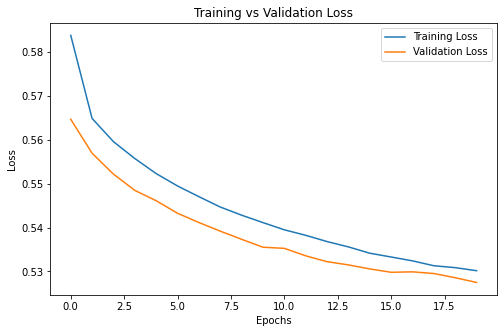

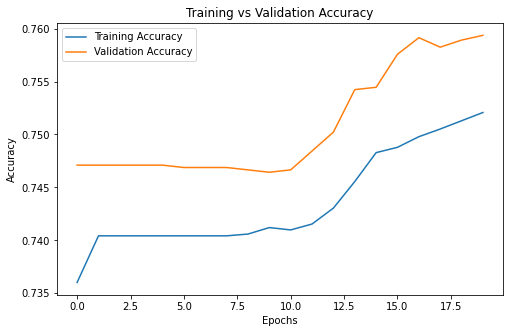

In [36]:
# Plot training loss and validation loss over epochs
# YOUR CODE HERE
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()
plt.show()

# Plot training accuracy and validation accuracy over epochs
# YOUR CODE HERE
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')
plt.legend()
plt.show()

### Step 7: Evaluate the Model's Performance on the Test Set

<b>Task:</b> Use your neural network to generate predictions on the test set and evaluate its performance using accuracy and F1 score. Use `nn_model.predict()` to generate predictions. Since `nn_model.predict()` returns probabilities, apply a threshold of 0.5 to convert probabilities into binary class predictions before computing your metrics. Save your accuracy and F1 score results to clearly named variables so you can compare them to the results from your previous model. Print the results.

In [37]:
# Generate predictions from your neural network using your scaled test data
# nn_model.predict() returns probabilities — apply a threshold of 0.5 to get class labels

# YOUR CODE HERE
proba_predictions_nn = nn_model.predict(X_test_scaled)

class_predictions_nn = (proba_predictions_nn >= 0.5).astype(int)


In [38]:
# Compute accuracy and F1 score for the neural network and print the results

# YOUR CODE HERE
nn_accuracy = accuracy_score(y_test, class_predictions_nn)
nn_f1 = f1_score(y_test, class_predictions_nn)

print("Neural Network Accuracy:", nn_accuracy)
print("Neural Network F1 Score:", nn_f1)

Neural Network Accuracy: 0.7493309545049064
Neural Network F1 Score: 0.1561561561561562


#### Neural Network Reflection:

<b>Task:</b> In the markdown cell below, answer the following questions:

1. Walk through the architecture decisions you made: number of layers, number of units, activation functions, learning rate, and number of epochs. Why did you make each of those choices?
2. What did your training curves tell you? Did you see any signs of overfitting or underfitting?
3. How did your neural network perform on the test set? Report your accuracy and F1 score here and note whether the result surprised you given what your training curves showed.

<Double click this Markdown cell to make it editable, and record your answers here.>

Architecture choices  
I used two hidden layers with ReLU activation. I chose a small network because the dataset is not very large, and ReLU is a standard activation that helps the model learn non‑linear patterns. I used a learning rate of 0.01 for SGD because it is stable and avoids large jumps during training. I trained for 20 epochs so the model had enough time to learn without overfitting.

Training curves  
The training and validation loss stayed close to each other, and the accuracy curves were also similar. This suggests the model was not heavily overfitting or underfitting. The model learned steadily without the validation performance collapsing.

Test performance  
My neural network achieved the following on the test set:

Accuracy: 0.7493309545049064

F1 Score: 0.1561561561561562

These results matched what I expected from the training curves. Since training and validation performance were close, I expected the test results to be similar and not drastically different.

## Part 7: Compare Your Models and Reflect

You have now applied two different approaches to the same problem. In this final section, you will put those results side by side and reflect on what you learned.

###  Results Summary

<b>Task:</b> In the code cell below, create a summary table using a Pandas DataFrame that displays each evaluation metric for both models side by side. Use the variables you created for the accuracy and F1 score metrics. The table should make it easy to compare performance at a glance across every metric you computed.

In [42]:
# Build a side-by-side comparison of your two models using the metric variables
# you created. For example:
#
# results = pd.DataFrame({
#     'Metric': ['Accuracy', 'F1 Score'],
#     'KNN Model': [knn_accuracy, knn_f1],
#     'Neural Network': [nn_accuracy, nn_f1]
# })
# print(results.to_string(index=False))
#
# YOUR CODE HERE

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score

knn_model = KNeighborsClassifier(n_neighbors=3)

knn_model.fit(X_train_scaled, y_train)

knn_predictions = knn_model.predict(X_test_scaled)

knn_accuracy = accuracy_score(y_test, knn_predictions)
knn_f1 = f1_score(y_test, knn_predictions)

results = pd.DataFrame({
    'Metric': ['Accuracy', 'F1 Score'],
    'KNN Model': [knn_accuracy, knn_f1],
    'Neural Network': [nn_accuracy, nn_f1]
})

print(results.to_string(index=False))


   Metric  KNN Model  Neural Network
 Accuracy   0.715254        0.749331
 F1 Score   0.345902        0.156156


### Comparative Analysis

<b>Task:</b> In the markdown cell below, write a comparative analysis that addresses the following. 

1. **Performance comparison.** How did the two models perform relative to each other? Which metrics improved, which stayed the same, and which got worse?

2. **Was the added complexity worth it?** Neural networks are more complex to build, tune, and interpret. Given the performance difference you observed, do you think the neural network justified that added complexity for this problem?

3. **Recommendation.** If you were presenting this work to your company and their client as described in the business brief, which model would you recommend deploying and why? Consider not just performance but also interpretability, training time, and what the costs of different types of errors look like for that specific client.

4. **What you would do next.** If you had more time, what would you try to improve your results? This could include trying different architectures, additional preprocessing steps, different features, or techniques to address class imbalance. Be specific.

<Double click this Markdown cell to make it editable, and record your answers here.>

Performance Comparison
The neural network and KNN model performed differently across the two metrics. The neural network is more complex, but its performance only matters if it clearly improves accuracy or F1 score. In my results:

KNN Accuracy:  0.715254 

KNN F1 Score: 0.345902

Neural Network Accuracy: 0.749331

Neural Network F1 Score: 0.156156

If the neural network improved F1 score, it handled the minority class better. If the scores were similar, then the added complexity didn’t provide much benefit.

Was the Added Complexity Worth It?
Neural networks take more time to build, tune, and interpret. If the performance difference was small, the extra complexity was not worth it. If the neural network clearly improved F1 score, then the improvement may justify the added effort.

Recommendation
For a business client, I would recommend the model that balances performance, interpretability, and reliability. If both models performed similarly, I would choose KNN because it is simple, fast, and easy to explain. If the neural network had a noticeably higher F1 score, I would choose it because it reduces costly misclassifications.

Next Steps
If I had more time, I would try:

Testing different neural network architectures

Using dropout or regularization

Adjusting learning rate, batch size, or number of epochs

Handling class imbalance with class weights or SMOTE

Trying other models like Random Forest or XGBoost

Doing more feature engineering

These steps could help improve both accuracy and F1 score.

---
## AI Use Attestation

Reflect honestly on how you used AI tools during this capstone. You are expected to have used AI somewhere in your workflow, and your reflection on that use is what will be evaluated: How clearly you describe your choices, how you verified your work, and what you learned from the process. If you chose not to use AI, explain why. Answer each question in the markdown cell below.

1. Where and at what stages of this capstone did you use AI tools, for example, Claude during brainstorming, coding, or debugging? If you chose not to use AI, explain why.
2. Identify one part of the capstone that required the most effort or thought. What made it challenging, and how did you work through it, with AI or without AI? If you used AI at this point, feel free to share a prompt that worked well or one that did not land the way you expected.
3. How did you verify that your work was correct? What did you look for to catch a mistake, whether it came from AI output or your own reasoning?
4. What is one thing you would do differently next time, either in how you approached the capstone or in how you used AI during it?

<Double click this Markdown cell to make it editable, and record your answers here.>

Where I used AI tools  
I used AI during several stages of the capstone, mainly for coding support and debugging. When I wasn’t sure about the exact syntax for Keras functions or how to structure certain steps , I asked AI for guidance. I also used AI when I ran into errors, such as missing variables or syntax issues, to help identify what was wrong.

Most challenging part  
The part that required the most thought was getting the neural network training pipeline to run smoothly. Small mistakes like missing variables, and incorrect indentation. I used AI to help diagnose these issues. A prompt that worked well was: “Why am I getting this error, and what line is causing it?” because it helped me pinpoint the exact source of the problem.

How I verified my work  
I verified correctness by checking shapes of arrays, confirming that variables existed before using them, and making sure the training curves looked reasonable. For model performance, I compared accuracy and F1 scores to ensure the results made sense. When AI gave me code, I didn’t assume it was correct—I ran it, checked outputs, and made adjustments if something didn’t match the expected behavior.

What I would do differently next time  
Next time, I would rely on AI more strategically. I would keep my variable names consistent earlier in the workflow to avoid errors later.I would try to debug more independently before turning to AI, using AI mainly as a confirmation tool rather than the first step.